In [2]:
from pathlib import Path

project_root = Path.cwd().parent
data_path = project_root / "data" / "raw" / "online_retail_II.xlsx"

print("Project folder:", project_root)
print("Dataset found:", data_path.exists())
print("Dataset path:", data_path)

Project folder: c:\Users\Tanya\Projects\CustomerDNA_Retail_Analytics
Dataset found: True
Dataset path: c:\Users\Tanya\Projects\CustomerDNA_Retail_Analytics\data\raw\online_retail_II.xlsx


In [3]:
import pandas as pd

excel_file = pd.ExcelFile(data_path)

print("Available sheets:", excel_file.sheet_names)

Available sheets: ['Year 2009-2010', 'Year 2010-2011']


Load a sample from each sheet

In [4]:
import pandas as pd

# Read only the first 10 rows from each sheet
sample_2009 = pd.read_excel(
    data_path,
    sheet_name="Year 2009-2010",
    nrows=10
)

sample_2010 = pd.read_excel(
    data_path,
    sheet_name="Year 2010-2011",
    nrows=10
)

print("2009–2010 sheet shape:", sample_2009.shape)
print("2010–2011 sheet shape:", sample_2010.shape)

print("\nColumns in the first sheet:")
print(sample_2009.columns.tolist())

print("\nFirst 5 rows from 2009–2010:")
display(sample_2009.head())

print("\nFirst 5 rows from 2010–2011:")
display(sample_2010.head())

2009–2010 sheet shape: (10, 8)
2010–2011 sheet shape: (10, 8)

Columns in the first sheet:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

First 5 rows from 2009–2010:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom



First 5 rows from 2010–2011:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


Load both years and inspect data quality

In [5]:
import pandas as pd

# Load both worksheets
df_2009 = pd.read_excel(
    data_path,
    sheet_name="Year 2009-2010"
)

df_2010 = pd.read_excel(
    data_path,
    sheet_name="Year 2010-2011"
)

# Combine both periods
df = pd.concat(
    [df_2009, df_2010],
    ignore_index=True
)

print("Combined dataset shape:", df.shape)
print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values by column:")
print(df.isna().sum())

print("\nFirst and last invoice dates:")
print("Start:", df["InvoiceDate"].min())
print("End:", df["InvoiceDate"].max())

Combined dataset shape: (1067371, 8)

Column data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

Missing values by column:
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

First and last invoice dates:
Start: 2009-12-01 07:45:00
End: 2011-12-09 12:50:00


What these results mean
- Customer ID: We cannot reliably assign every transaction to a known customer. We'll preserve these records for suitable overall sales analysis but exclude unidentified customers from customer-level RFM segmentation.
- Description: A small number of product lines have missing descriptions. We'll investigate whether their other fields still support sales calculations.
- Data types: Invoice and StockCode are stored as text-like objects. That's appropriate for identifiers; we should not treat invoice numbers as numerical measurements.
- Date coverage: The recorded data runs from December 2009 to December 2011. We'll verify the distribution of transactions by year and month before drawing conclusions about trends.
These are data-quality observations, not sales or customer-behavior findings yet.

Check cancellations, quantities, prices and duplicates

In [6]:
# 1. Check duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# 2. Check negative, zero and positive quantities
print("\nQuantity categories:")
print(
    pd.Series({
        "Negative quantities": (df["Quantity"] < 0).sum(),
        "Zero quantities": (df["Quantity"] == 0).sum(),
        "Positive quantities": (df["Quantity"] > 0).sum()
    })
)

# 3. Check negative, zero and positive prices
print("\nPrice categories:")
print(
    pd.Series({
        "Negative prices": (df["Price"] < 0).sum(),
        "Zero prices": (df["Price"] == 0).sum(),
        "Positive prices": (df["Price"] > 0).sum()
    })
)

# 4. Check invoices beginning with C
invoice_text = df["Invoice"].astype(str).str.strip()

print("\nInvoices beginning with C:",
      invoice_text.str.upper().str.startswith("C").sum())

# 5. Inspect the distributions
print("\nQuantity summary:")
print(df["Quantity"].describe())

print("\nPrice summary:")
print(df["Price"].describe())


Exact duplicate rows: 34335

Quantity categories:
Negative quantities      22950
Zero quantities              0
Positive quantities    1044421
dtype: int64

Price categories:
Negative prices          5
Zero prices           6202
Positive prices    1061164
dtype: int64

Invoices beginning with C: 19494

Quantity summary:
count    1.067371e+06
mean     9.938898e+00
std      1.727058e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64

Price summary:
count    1.067371e+06
mean     4.649388e+00
std      1.235531e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: Price, dtype: float64


Interpret the initial findings

34,335 exact duplicate rows
These may include repeated transaction lines. We should inspect examples before removing them, because repeated-looking rows are not automatically errors.

19,494 rows with invoice IDs beginning with C
These are cancellation candidates. We'll compare them with negative quantities and inspect sample invoices rather than assuming the two counts are identical.

22,950 negative quantities
These could represent returns or other adjustments. They need separate treatment in sales and customer analyses.

6,202 zero-price rows and 5 negative-price rows
These could include promotional items, unusual records, or corrections. We'll inspect their descriptions and quantities before deciding whether they belong in revenue calculations.

Inspect the suspicious records

In [7]:
# Create flags for records that need investigation
invoice_text = df["Invoice"].astype(str).str.strip()

cancellation_mask = invoice_text.str.upper().str.startswith("C")
negative_quantity_mask = df["Quantity"] < 0
zero_price_mask = df["Price"] == 0
negative_price_mask = df["Price"] < 0

# Inspect a few cancellation records
print("Sample cancellation records:")
display(
    df.loc[cancellation_mask].head(10)
)

# Inspect negative quantities
print("\nSample negative-quantity records:")
display(
    df.loc[negative_quantity_mask].head(10)
)

# Inspect zero-price records
print("\nSample zero-price records:")
display(
    df.loc[zero_price_mask].head(10)
)

# Inspect negative-price records
print("\nNegative-price records:")
display(
    df.loc[negative_price_mask]
)


Sample cancellation records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom



Sample negative-quantity records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom



Sample zero-price records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom



Negative-price records:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Cancellation examples: invoice IDs such as C489449 contain negative quantities.

Zero-price records: some descriptions contain terms such as damages, lost, and mixed, with missing customer IDs. These should be investigated rather than treated as ordinary sales.

Negative-price records: the five examples are labelled Adjust bad debt, so they are accounting adjustments, not ordinary product sales.

Cleaning decision: we'll preserve the original df and create a separate analysis dataset after defining the rules.

Check whether cancellation invoices always have negative quantities

In [8]:
invoice_text = df["Invoice"].astype(str).str.strip()
is_cancellation = invoice_text.str.upper().str.startswith("C")

print("Cancellation invoice rows:")
print(is_cancellation.sum())

print("\nCancellation rows with negative quantity:")
print((is_cancellation & (df["Quantity"] < 0)).sum())

print("\nCancellation rows with zero quantity:")
print((is_cancellation & (df["Quantity"] == 0)).sum())

print("\nCancellation rows with positive quantity:")
print((is_cancellation & (df["Quantity"] > 0)).sum())

print("\nNegative quantities without a C-prefixed invoice:")
print(((~is_cancellation) & (df["Quantity"] < 0)).sum())

print("\nSample negative quantities without C-prefixed invoices:")
display(
    df.loc[(~is_cancellation) & (df["Quantity"] < 0)].head(10)
)


Cancellation invoice rows:
19494

Cancellation rows with negative quantity:
19493

Cancellation rows with zero quantity:
0

Cancellation rows with positive quantity:
1

Negative quantities without a C-prefixed invoice:
3457

Sample negative quantities without C-prefixed invoices:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom


Define a transparent sales-analysis policy

In [9]:
# Identify cancellation invoices
invoice_text = df["Invoice"].astype(str).str.strip()
is_cancellation = invoice_text.str.upper().str.startswith("C")

# Calculate line-level value for inspection
df_check = df.copy()
df_check["LineValue"] = df_check["Quantity"] * df_check["Price"]

# Summarize broad transaction categories
print("Total rows:", len(df_check))
print("C-prefixed invoice rows:", is_cancellation.sum())
print("Negative-quantity rows:", (df_check["Quantity"] < 0).sum())
print("Zero-price rows:", (df_check["Price"] == 0).sum())
print("Negative-price rows:", (df_check["Price"] < 0).sum())

print("\nLine-value summary:")
print(df_check["LineValue"].describe())

print("\nTotal line value, including all records:",
      round(df_check["LineValue"].sum(), 2))

print("\nLine value for C-prefixed invoices:",
      round(df_check.loc[is_cancellation, "LineValue"].sum(), 2))

print("\nLine value for negative-price records:",
      round(df_check.loc[df_check["Price"] < 0, "LineValue"].sum(), 2))

Total rows: 1067371
C-prefixed invoice rows: 19494
Negative-quantity rows: 22950
Zero-price rows: 6202
Negative-price rows: 5

Line-value summary:
count    1.067371e+06
mean     1.806987e+01
std      2.924202e+02
min     -1.684696e+05
25%      3.750000e+00
50%      9.900000e+00
75%      1.770000e+01
max      1.684696e+05
Name: LineValue, dtype: float64

Total line value, including all records: 19287250.57

Line value for C-prefixed invoices: -1526667.86

Line value for negative-price records: -158676.14


Investigate duplicates before removing them

In [10]:
# Find exact duplicate rows without changing the original dataset
duplicate_mask = df.duplicated(keep=False)

print("Rows belonging to duplicate groups:", duplicate_mask.sum())

print("\nSample duplicate rows:")
display(
    df.loc[duplicate_mask]
      .sort_values(["Invoice", "StockCode", "InvoiceDate"])
      .head(20)
)

# Measure the line value associated with duplicate rows
df_duplicates = df.loc[duplicate_mask].copy()
df_duplicates["LineValue"] = (
    df_duplicates["Quantity"] * df_duplicates["Price"]
)

print("\nRows in duplicate groups:", len(df_duplicates))
print("Total line value of all rows in duplicate groups:",
      round(df_duplicates["LineValue"].sum(), 2))

print("\nDuplicate counts by invoice:")
print(
    df_duplicates.groupby("Invoice").size()
      .sort_values(ascending=False)
      .head(10)
)


Rows belonging to duplicate groups: 67242

Sample duplicate rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom



Rows in duplicate groups: 67242
Total line value of all rows in duplicate groups: 857785.64

Duplicate counts by invoice:
Invoice
537434    1350
538071    1304
537638    1202
537237    1194
536876    1186
536592    1184
537823    1182
537240    1136
537666    1072
536544    1054
dtype: int64


Measure the actual effect of removing exact duplicates

In [11]:
# Create a separate dataset for comparison
df_deduplicated = df.drop_duplicates().copy()

# Calculate line values in both versions
df_original_check = df.copy()
df_original_check["LineValue"] = (
    df_original_check["Quantity"] * df_original_check["Price"]
)

df_deduplicated["LineValue"] = (
    df_deduplicated["Quantity"] * df_deduplicated["Price"]
)

print("Original row count:", len(df))
print("After exact deduplication:", len(df_deduplicated))
print("Rows removed:", len(df) - len(df_deduplicated))

print("\nOriginal total line value:",
      round(df_original_check["LineValue"].sum(), 2))

print("Total line value after exact deduplication:",
      round(df_deduplicated["LineValue"].sum(), 2))

print("Difference in line value:",
      round(
          df_original_check["LineValue"].sum()
          - df_deduplicated["LineValue"].sum(),
          2
      ))


Original row count: 1067371
After exact deduplication: 1033036
Rows removed: 34335

Original total line value: 19287250.57
Total line value after exact deduplication: 18855533.7
Difference in line value: 431716.87


Check the effect of duplicates on different transaction types

In [12]:

def transaction_summary(data, label):
    invoice_text = data["Invoice"].astype(str).str.strip()
    is_cancellation = invoice_text.str.upper().str.startswith("C")

    line_value = data["Quantity"] * data["Price"]

    print(f"\n{label}")
    print("-" * len(label))
    print("Rows:", len(data))
    print("Positive-quantity rows:", (data["Quantity"] > 0).sum())
    print("Negative-quantity rows:", (data["Quantity"] < 0).sum())
    print("C-prefixed invoice rows:", is_cancellation.sum())
    print("Exact duplicate rows remaining:", data.duplicated().sum())
    print("Total line value:", round(line_value.sum(), 2))

transaction_summary(df, "Original dataset")
transaction_summary(df_deduplicated, "After exact deduplication")



Original dataset
----------------
Rows: 1067371
Positive-quantity rows: 1044421
Negative-quantity rows: 22950
C-prefixed invoice rows: 19494
Exact duplicate rows remaining: 34335
Total line value: 19287250.57

After exact deduplication
-------------------------
Rows: 1033036
Positive-quantity rows: 1010540
Negative-quantity rows: 22496
C-prefixed invoice rows: 19104
Exact duplicate rows remaining: 0
Total line value: 18855533.7


Build the preliminary cleaning report

In [13]:

# Initial data-quality report
quality_report = pd.DataFrame({
    "Metric": [
        "Original rows",
        "Exact duplicate rows removed",
        "Rows after exact deduplication",
        "Missing descriptions",
        "Missing customer IDs",
        "Negative-quantity rows (deduplicated)",
        "Zero-price rows (deduplicated)",
        "Negative-price rows (deduplicated)",
        "C-prefixed invoice rows (deduplicated)"
    ],
    "Value": [
        len(df),
        len(df) - len(df_deduplicated),
        len(df_deduplicated),
        df_deduplicated["Description"].isna().sum(),
        df_deduplicated["Customer ID"].isna().sum(),
        (df_deduplicated["Quantity"] < 0).sum(),
        (df_deduplicated["Price"] == 0).sum(),
        (df_deduplicated["Price"] < 0).sum(),
        df_deduplicated["Invoice"].astype(str)
            .str.strip().str.upper().str.startswith("C").sum()
    ]
})

display(quality_report)


,Metric,Value
0,Original rows,1067371
1,Exact duplicate rows removed,34335
2,Rows after exact deduplication,1033036
3,Missing descriptions,4275
4,Missing customer IDs,235151
5,Negative-quantity rows (deduplicated),22496
6,Zero-price rows (deduplicated),6014
7,Negative-price rows (deduplicated),5
8,C-prefixed invoice rows (deduplicated),19104


Create the provisional datasets

In [14]:

# Start from the deduplicated data
analysis_df = df_deduplicated.copy()

# Standardize invoice text for filtering
invoice_text = analysis_df["Invoice"].astype(str).str.strip()
is_cancellation = invoice_text.str.upper().str.startswith("C")

# Separate ordinary positive-value product lines
sales_mask = (
    (analysis_df["Quantity"] > 0)
    & (analysis_df["Price"] > 0)
    & (~is_cancellation)
)

sales_df = analysis_df.loc[sales_mask].copy()
sales_df["LineValue"] = sales_df["Quantity"] * sales_df["Price"]

# Retain customer-identified sales for RFM analysis
customer_df = sales_df.loc[
    sales_df["Customer ID"].notna()
].copy()

# Keep cancellation and return records available separately
returns_df = analysis_df.loc[
    is_cancellation | (analysis_df["Quantity"] < 0)
].copy()

print("Deduplicated dataset:", analysis_df.shape)
print("Provisional sales dataset:", sales_df.shape)
print("Customer-identified sales dataset:", customer_df.shape)
print("Returns/cancellations dataset:", returns_df.shape)

print("\nProvisional positive-sales line value:",
      round(sales_df["LineValue"].sum(), 2))

print("Sales rows without Customer ID:",
      sales_df["Customer ID"].isna().sum())


Deduplicated dataset: (1033036, 9)
Provisional sales dataset: (1007913, 9)
Customer-identified sales dataset: (779425, 9)
Returns/cancellations dataset: (22497, 9)

Provisional positive-sales line value: 20476260.45
Sales rows without Customer ID: 228488


Validate the provisional sales dataset

In [15]:

# Validate the sales filter and its monetary values

print("Any non-positive quantities in sales_df:",
      (sales_df["Quantity"] <= 0).any())

print("Any non-positive prices in sales_df:",
      (sales_df["Price"] <= 0).any())

print("Any C-prefixed invoices in sales_df:",
      sales_df["Invoice"].astype(str)
      .str.strip().str.upper().str.startswith("C").any())

print("\nLine value reconciliation:")
print("All records:", round(
    (analysis_df["Quantity"] * analysis_df["Price"]).sum(), 2
))
print("Provisional sales:", round(sales_df["LineValue"].sum(), 2))
print("Difference:", round(
    sales_df["LineValue"].sum()
    - (analysis_df["Quantity"] * analysis_df["Price"]).sum(), 2
))

print("\nSales value by year:")
sales_df.groupby(
    sales_df["InvoiceDate"].dt.year
)["LineValue"].agg(["count", "sum"])


Any non-positive quantities in sales_df: False
Any non-positive prices in sales_df: False
Any C-prefixed invoices in sales_df: False

Line value reconciliation:
All records: 18855533.7
Provisional sales: 20476260.45
Difference: 1620726.75

Sales value by year:


,count,sum
InvoiceDate,,
2009,43453,822483.950
2010,480572,9833100.424
2011,483888,9820676.074


Identify which excluded records explain the difference

In [16]:

# Work on a separate copy for reconciliation
recon = analysis_df.copy()

invoice_text = recon["Invoice"].astype(str).str.strip()
is_cancellation = invoice_text.str.upper().str.startswith("C")

# Mutually exclusive categories, in priority order
conditions = [
    is_cancellation,
    recon["Price"] < 0,
    recon["Quantity"] < 0,
    recon["Price"] == 0,
    recon["Quantity"] > 0
]

labels = [
    "C-prefixed invoices",
    "Negative price (non-C)",
    "Negative quantity (non-C, non-negative price)",
    "Zero price (remaining records)",
    "Positive quantity and positive price"
]

recon["Category"] = pd.Series(
    pd.NA, index=recon.index, dtype="object"
)

for condition, label in zip(conditions, labels):
    recon.loc[
        recon["Category"].isna() & condition, "Category"
    ] = label

recon["LineValue"] = recon["Quantity"] * recon["Price"]

reconciliation = recon.groupby(
    "Category", dropna=False
).agg(
    Rows=("Invoice", "size"),
    LineValue=("LineValue", "sum")
).sort_values("Rows", ascending=False)

display(reconciliation.round(2))

print("\nReconciliation total:",
      round(recon["LineValue"].sum(), 2))
print("Expected all-record total:",
      round((analysis_df["Quantity"] * analysis_df["Price"]).sum(), 2))


,Rows,LineValue
Category,,
Positive quantity and positive price,1007913,20476260.45
C-prefixed invoices,19104,-1462050.61
"Negative quantity (non-C, non-negative price)",3393,0.00
Zero price (remaining records),2621,0.00
Negative price (non-C),5,-158676.14



Reconciliation total: 18855533.7
Expected all-record total: 18855533.7


The total line value matches exactly between your category-based reconciliation and the deduplicated dataset.
- Reconciliation total: 18,855,533.70
- Expected all-record total: 18,855,533.70
- Difference: 0.00
This confirms that the category reconciliation has preserved the overall line-value total. It does not yet prove that every record has been classified correctly or that the total represents final business revenue.

Verify the transaction categories - table shows that the non-C negative-quantity records have a line value of exactly zero

In [17]:
negative_qty_check = recon.loc[
    (~is_cancellation) & (recon["Quantity"] < 0),
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "LineValue"]
]

display(negative_qty_check.head(10))

,Invoice,StockCode,Description,Quantity,Price,LineValue
263,489464,21733,85123a mixed,-96,0.0,-0.0
283,489463,71477,short,-240,0.0,-0.0
284,489467,85123A,21733 mixed,-192,0.0,-0.0
470,489521,21646,NaN,-50,0.0,-0.0
3114,489655,20683,NaN,-44,0.0,-0.0
3162,489660,35956,lost,-1043,0.0,-0.0
3168,489663,35605A,damages,-117,0.0,-0.0
4296,489806,18010,NaN,-770,0.0,-0.0
4538,489820,21133,invcd as 84879?,-720,0.0,-0.0
4566,489821,85049G,NaN,-240,0.0,-0.0


Check how many records have these descriptions - These records have negative quantities but a price of zero, so their line value is zero. Descriptions such as mixed, short, lost, and damages suggest they may represent stock discrepancies or operational adjustments rather than ordinary sales.

In [18]:
# Inspect descriptions on non-C invoices with negative quantities
negative_qty_records = recon.loc[
    (~is_cancellation) & (recon["Quantity"] < 0)
].copy()

print("Total records:", len(negative_qty_records))
print("\nDescription counts:")
display(
    negative_qty_records["Description"]
    .fillna("Missing description")
    .value_counts()
    .head(20)
)

print("\nPrice distribution:")
display(negative_qty_records["Price"].value_counts().head(10))

Total records: 3393

Description counts:


Description
Missing description       2633
check                      121
damages                     83
?                           81
damaged                     78
missing                     27
sold as set on dotcom       20
Damaged                     17
smashed                      9
thrown away                  9
Unsaleable, destroyed.       9
dotcom                       8
damages?                     7
??                           7
crushed                      6
given away                   6
MIA                          5
Damages                      5
counted                      5
checked                      5
Name: count, dtype: int64


Price distribution:


Price
0.0    3393
Name: count, dtype: int64

In [19]:
print("Sales rows:", len(sales_df))
print("Unique invoices:", sales_df["Invoice"].nunique())
print("Unique products:", sales_df["StockCode"].nunique())
print("Unique customers:", sales_df["Customer ID"].nunique())
print("Date range:", sales_df["InvoiceDate"].min(),
      "to", sales_df["InvoiceDate"].max())
print("Total line value:", round(sales_df["LineValue"].sum(), 2))

Sales rows: 1007913
Unique invoices: 40077
Unique products: 4917
Unique customers: 5878
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Total line value: 20476260.45


Build monthly sales KPIs

In [20]:

# Monthly sales performance
monthly_sales = sales_df.copy()

monthly_sales["Month"] = (
    monthly_sales["InvoiceDate"].dt.to_period("M")
)

monthly_kpis = (
    monthly_sales.groupby("Month")
    .agg(
        Sales_Line_Value=("LineValue", "sum"),
        Invoice_Count=("Invoice", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Unique_Customers=("Customer ID", "nunique"),
    )
    .reset_index()
)

monthly_kpis["Month"] = monthly_kpis["Month"].astype(str)

monthly_kpis["Average_Order_Value"] = (
    monthly_kpis["Sales_Line_Value"]
    / monthly_kpis["Invoice_Count"]
)

display(monthly_kpis.head(12).round(2))
print("Number of months:", len(monthly_kpis))
print("Monthly data shape:", monthly_kpis.shape)


,Month,Sales_Line_Value,Invoice_Count,Units_Sold,Unique_Customers,Average_Order_Value
0,2009-12,822483.95,1682,425461,955,488.99
1,2010-01,651155.11,1105,390672,720,589.28
2,2010-02,551504.73,1201,381879,772,459.20
3,2010-03,830915.26,1681,526026,1057,494.30
4,2010-04,678875.25,1462,366705,942,464.35
5,2010-05,657705.50,1500,395868,966,438.47
6,2010-06,749537.31,1645,406820,1041,455.65
7,2010-07,648810.27,1529,337895,928,424.34
8,2010-08,695251.91,1425,472380,911,487.90
9,2010-09,921696.99,1839,583864,1145,501.19


Number of months: 25
Monthly data shape: (25, 6)


Visualize monthly sales

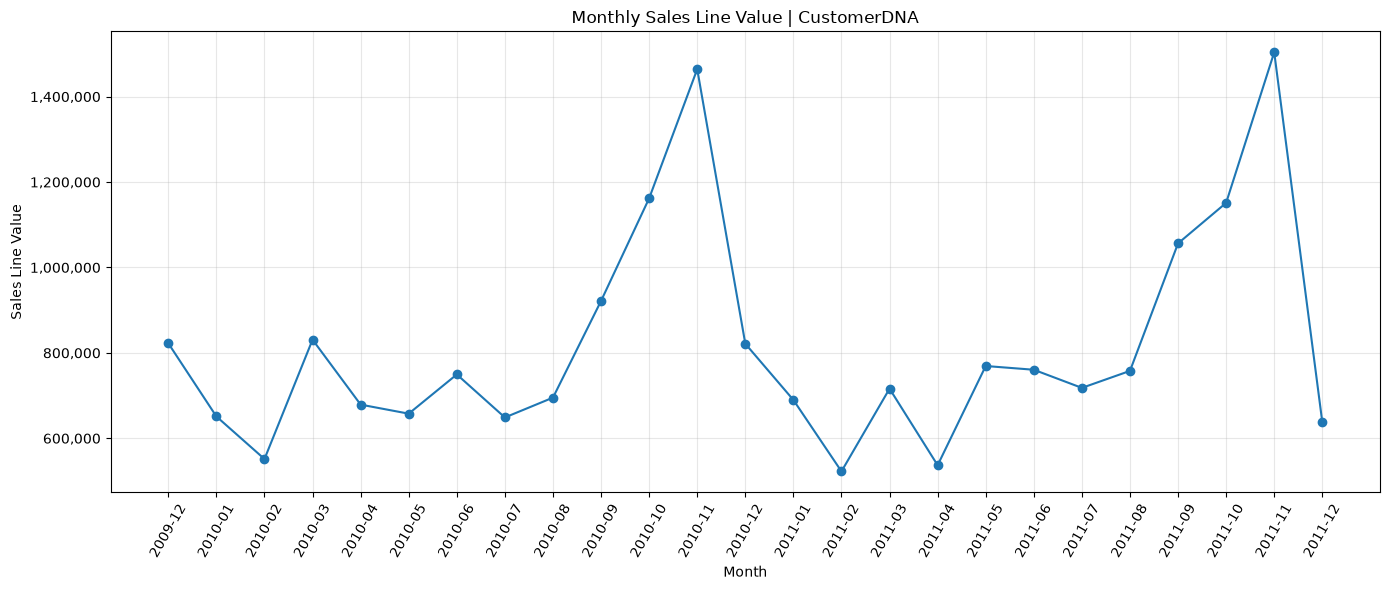

In [21]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_kpis["Month"],
    monthly_kpis["Sales_Line_Value"],
    marker="o"
)

plt.title("Monthly Sales Line Value | CustomerDNA")
plt.xlabel("Month")
plt.ylabel("Sales Line Value")
plt.xticks(rotation=60)
plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


What we can observe
- November 2010: approximately 1.46 million in sales line value.
- November 2011: approximately 1.50 million, the highest point on the chart.
- February 2011: approximately 520,000, one of the lowest months.
- December 2011: approximately 640,000, but this month only has data through December 9, so it is not comparable to a complete month.
The November peaks could indicate stronger year-end shopping demand, but two annual observations are not enough to establish a reliable seasonal pattern.

Analyze monthly invoice counts

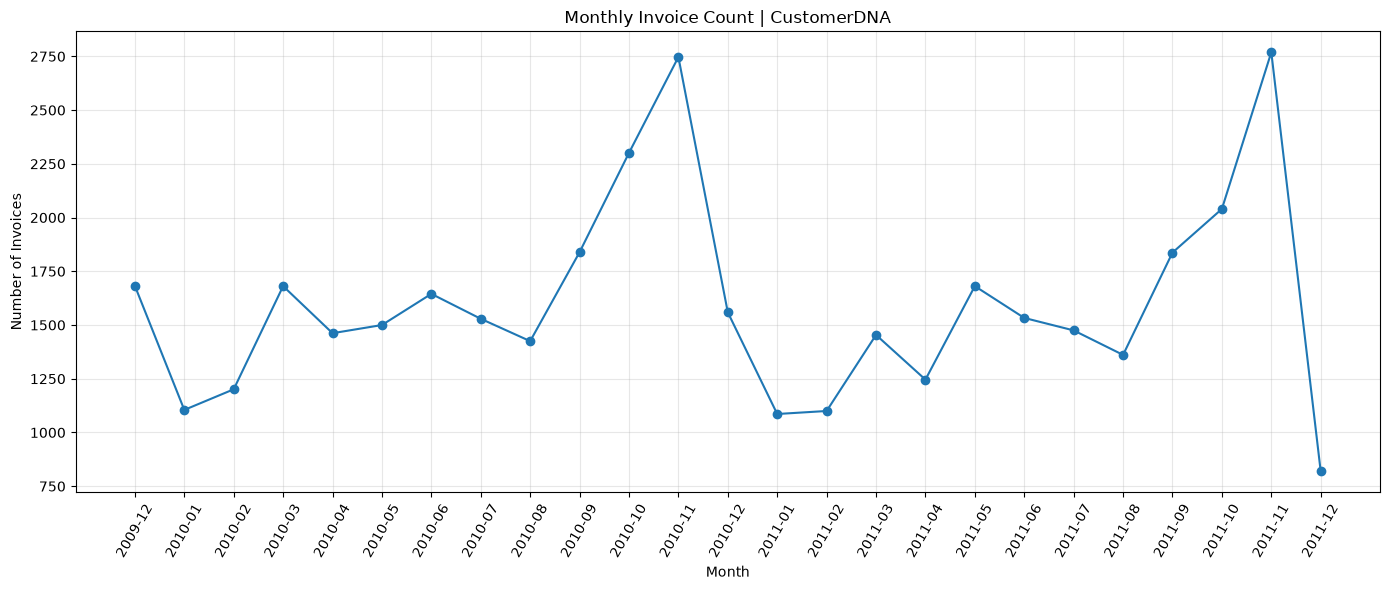

In [22]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_kpis["Month"],
    monthly_kpis["Invoice_Count"],
    marker="o"
)

plt.title("Monthly Invoice Count | CustomerDNA")
plt.xlabel("Month")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


What the two charts tell us
- November 2010: 2,747 invoices and 1,464,293.14 in sales line value.
- November 2011: approximately 2,767 invoices, with sales line value around 1.50 million.
- December 2011: the invoice count falls to around 820, but the dataset ends on December 9, so this is a partial month.

Compare monthly order value

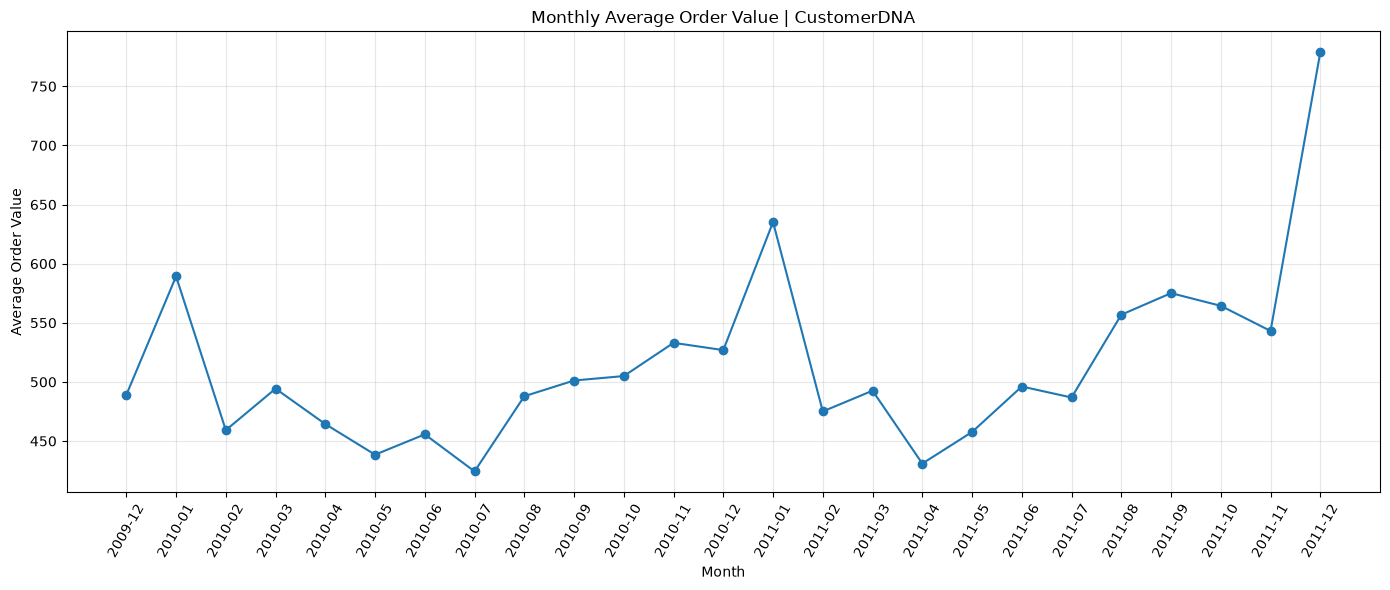

In [23]:

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_kpis["Month"],
    monthly_kpis["Average_Order_Value"],
    marker="o"
)

plt.title("Monthly Average Order Value | CustomerDNA")
plt.xlabel("Month")
plt.ylabel("Average Order Value")
plt.xticks(rotation=60)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


What the chart tells us
- December 2011 has the highest average order value, approximately 778. However, this is a partial month ending December 9, so it is not directly comparable with full months.
- January 2011 shows an average order value of approximately 636, higher than the preceding months.
- November 2010 and November 2011 have high sales and invoice counts, while their average order values are comparatively moderate. This suggests that the number of invoices contributes substantially to the November sales peaks.

Save the monthly KPI table

In [24]:

from pathlib import Path

project_root = Path.cwd().parent
output_path = project_root / "data" / "processed" / "monthly_sales_kpis.csv"

output_path.parent.mkdir(parents=True, exist_ok=True)

monthly_kpis.to_csv(output_path, index=False)

print("Monthly KPI file saved to:", output_path)
print("File exists:", output_path.exists())
print("Rows saved:", len(monthly_kpis))


Monthly KPI file saved to: c:\Users\Tanya\Projects\CustomerDNA_Retail_Analytics\data\processed\monthly_sales_kpis.csv
File exists: True
Rows saved: 25


Build the customer-level RFM dataset

RFM stands for:
- Recency: How recently a customer purchased.
- Frequency: How many distinct invoices a customer placed.
- Monetary: The total transaction line value associated with that customer.

In [25]:
import pandas as pd
from pathlib import Path

# Reference date: one day after the last recorded invoice date
reference_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Aggregate transactions at customer level
rfm = (
    customer_df.groupby("Customer ID")
    .agg(
        Recency=(
            "InvoiceDate",
            lambda dates: (reference_date - dates.max()).days
        ),
        Frequency=("Invoice", "nunique"),
        Monetary=("LineValue", "sum")
    )
    .reset_index()
)

# Basic validation
print("Number of customers:", len(rfm))
print("Duplicate customer IDs:", rfm["Customer ID"].duplicated().sum())
print("\nRFM summary:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(2))

print("\nSample customers:")
display(rfm.head(10).round(2))


Number of customers: 5878
Duplicate customer IDs: 0

RFM summary:


,Recency,Frequency,Monetary
count,5878.00,5878.00,5878.00
mean,201.33,6.29,2955.90
std,209.34,13.01,14440.85
min,1.00,1.00,2.95
25%,26.00,1.00,342.28
50%,96.00,3.00,867.74
75%,380.00,7.00,2248.30
max,739.00,398.00,580987.04



Sample customers:


,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,2019.40
3,12349.0,19,4,4428.69
4,12350.0,310,1,334.40
5,12351.0,375,1,300.93
6,12352.0,36,10,2849.84
7,12353.0,204,2,406.76
8,12354.0,232,1,1079.40
9,12355.0,214,2,947.61


What your RFM results tell us
Metric	Median	Mean	Interpretation
Recency	96 days	201.33 days	Half of customers last purchased within 96 days of the reference date.
Frequency	3 invoices	6.29 invoices	The typical customer placed relatively few orders, while some purchased frequently.
Monetary	867.74	2,955.90	Customer spending is strongly right-skewed, with a smaller number of high-value customers.
Three observations stand out:
- Customer spending is highly uneven. Maximum monetary value is 580,987.04, compared with a median of 867.74.
- Purchase frequency varies substantially. The maximum is 398 distinct invoices, while the median is only 3.
- Recency is also dispersed. Some customers purchased very recently, while others have not purchased for more than 700 days.
These differences make RFM a useful foundation for customer segmentation. They also mean we should handle skewness and scaling carefully before clustering.

Visualize the RFM distributions

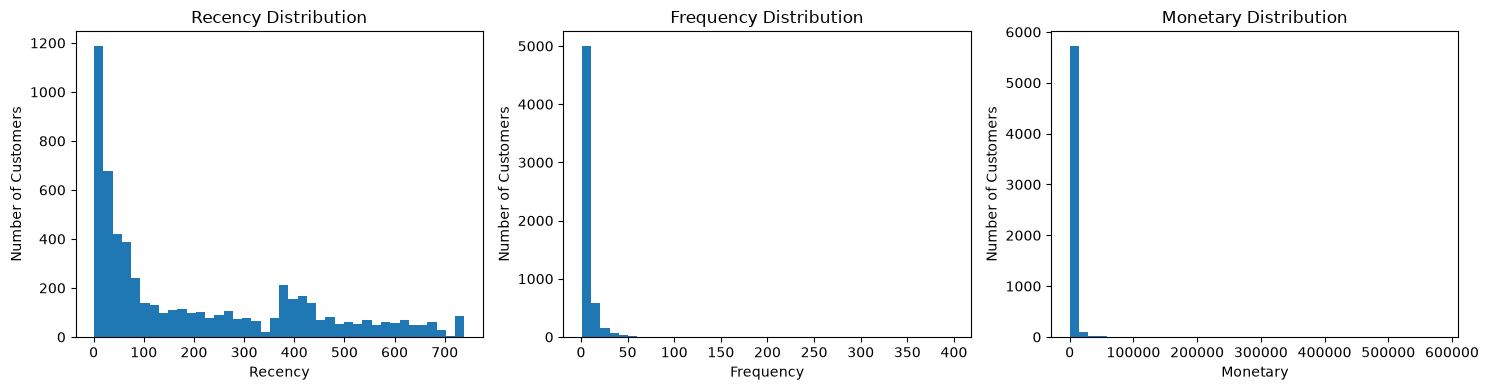

In [26]:
import matplotlib.pyplot as plt

rfm_metrics = ["Recency", "Frequency", "Monetary"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric in zip(axes, rfm_metrics):
    ax.hist(rfm[metric], bins=40)
    ax.set_title(f"{metric} Distribution")
    ax.set_xlabel(metric)
    ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()


Recency
Most customers are concentrated toward lower recency values, while a long tail extends beyond 700 days. The smaller concentration around 365–450 days is worth investigating, but we shouldn't assume it represents a distinct segment yet.

Frequency
Most customers have few invoices, while a small number have very high purchase frequency. The maximum of 398 invoices is a potential influential observation.

Monetary
Spending is extremely concentrated near the lower end, with a few customers spending much more than the rest. The maximum of 580,987.04 could strongly influence K-Means if we use the raw values.

Apply a log transformation and standardization

In [27]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Preserve original RFM data
rfm_model = rfm.copy()

# Log-transform the three RFM variables
rfm_log = rfm_model[["Recency", "Frequency", "Monetary"]].copy()
rfm_log = np.log1p(rfm_log)

# Standardize transformed features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to a DataFrame for easier inspection
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm_model.index
)

print("Scaled dataset shape:", rfm_scaled_df.shape)
print("\nMeans (should be near 0):")
display(rfm_scaled_df.mean().round(4))

print("\nStandard deviations (should be near 1):")
display(rfm_scaled_df.std(ddof=0).round(4))

print("\nFirst five scaled rows:")
display(rfm_scaled_df.head().round(3))


Scaled dataset shape: (5878, 3)

Means (should be near 0):


Recency     -0.0
Frequency    0.0
Monetary     0.0
dtype: float64


Standard deviations (should be near 1):


Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64


First five scaled rows:


,Recency,Frequency,Monetary
0,0.857,1.254,3.206
1,-2.152,0.800,1.216
2,-0.079,0.299,0.573
3,-0.935,0.074,1.140
4,0.825,-1.058,-0.723


Evaluate the number of clusters

We'll compare K-Means models with different cluster counts using two measures:
- Inertia: Measures within-cluster variation. It generally decreases as the number of clusters increases, so we'll look for an elbow rather than simply choosing the lowest value.
- Silhouette score: Measures how well-separated the clusters are. Higher scores generally indicate better separation, although interpretability and segment usefulness also matter.

,K,Inertia,Silhouette_Score
0,2,8588.9853,0.4386
1,3,6354.3432,0.3477
2,4,4921.2333,0.3650
3,5,4099.1061,0.3425
4,6,3554.6963,0.3348
5,7,3194.5010,0.3066
6,8,2902.4339,0.3033
7,9,2656.5623,0.2925
8,10,2467.3785,0.2905


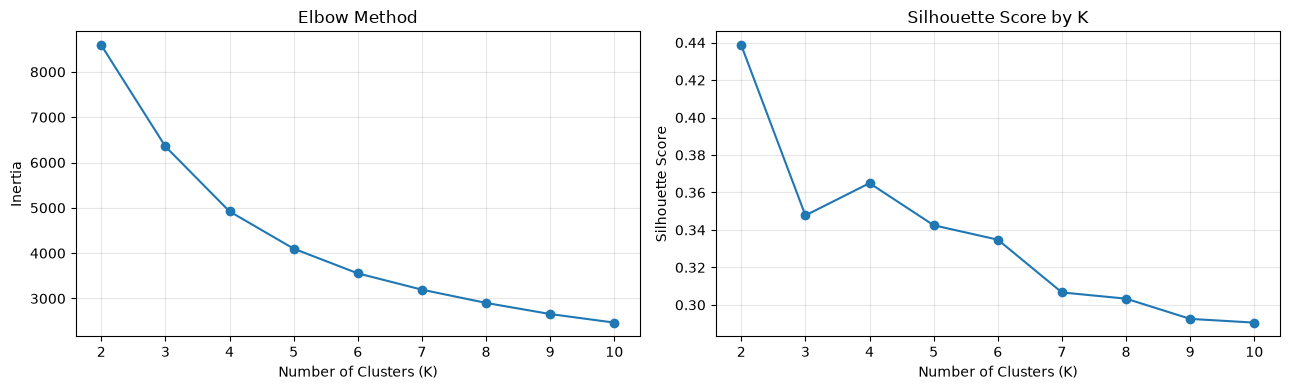

In [28]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled_df)

    results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette_Score": silhouette_score(
            rfm_scaled_df, labels
        )
    })

cluster_results = pd.DataFrame(results)

display(cluster_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    cluster_results["K"],
    cluster_results["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    cluster_results["K"],
    cluster_results["Silhouette_Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score by K")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


K	Silhouette score	Interpretation
2	0.4386	Best separation among the tested options
3	0.3477	Lower separation
4	0.3650	Some improvement over K=3
5	0.3425	Separation declines
6–10	0.3348 → 0.2905	Generally declining separation

The elbow chart shows diminishing improvements as K increases. The silhouette score is highest at K = 2, although that doesn't automatically make two segments the best business solution. Four clusters also deserve consideration because their silhouette score is better than those for three and five clusters

Compare K=2 and K=4, then examine segment sizes and customer profiles. We shouldn't select K=4 merely because it creates more detailed segment

Fit both models and compare the segments

In [29]:
from sklearn.cluster import KMeans
import pandas as pd

candidate_models = {}
candidate_labels = {}

for k in [2, 4]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled_df)

    candidate_models[k] = model
    candidate_labels[k] = labels

    print(f"\n--- K = {k} ---")

    segment_sizes = (
        pd.Series(labels, name="Segment")
        .value_counts()
        .sort_index()
        .rename("Customers")
        .to_frame()
    )

    segment_sizes["Customer_Percentage"] = (
        segment_sizes["Customers"] / len(rfm) * 100
    )

    display(segment_sizes.round(2))



--- K = 2 ---


,Customers,Customer_Percentage
Segment,,
0,3558,60.53
1,2320,39.47



--- K = 4 ---


,Customers,Customer_Percentage
Segment,,
0,1973,33.57
1,1250,21.27
2,1196,20.35
3,1459,24.82


K = 2: 60.53% and 39.47% of customers.
K = 4: segment sizes range from 20.35% to 33.57% of customers.

Compare RFM profiles

In [30]:
rfm_comparison = rfm.copy()

for k, labels in candidate_labels.items():
    rfm_comparison[f"Segment_K{k}"] = labels

for k in [2, 4]:
    print(f"\n{'=' * 15} K = {k} {'=' * 15}")

    segment_profile = (
        rfm_comparison
        .groupby(f"Segment_K{k}")
        .agg(
            Customers=("Customer ID", "count"),
            Median_Recency=("Recency", "median"),
            Median_Frequency=("Frequency", "median"),
            Median_Monetary=("Monetary", "median"),
            Mean_Recency=("Recency", "mean"),
            Mean_Frequency=("Frequency", "mean"),
            Mean_Monetary=("Monetary", "mean"),
        )
    )

    segment_profile["Customer_Percentage"] = (
        segment_profile["Customers"] / len(rfm_comparison) * 100
    )

    display(segment_profile.round(2))



=============== K = 2 ===============


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Mean_Recency,Mean_Frequency,Mean_Monetary,Customer_Percentage
Segment_K2,,,,,,,,
0,3558,289.5,2.0,415.80,299.65,2.10,614.34,60.53
1,2320,24.0,8.0,2861.48,50.56,12.72,6546.97,39.47



=============== K = 4 ===============


,Customers,Median_Recency,Median_Frequency,Median_Monetary,Mean_Recency,Mean_Frequency,Mean_Monetary,Customer_Percentage
Segment_K4,,,,,,,,
0,1973,402.0,1.0,273.31,394.95,1.38,317.08,33.57
1,1250,24.0,3.0,734.12,28.30,3.05,857.49,21.27
2,1196,17.0,13.0,4986.12,27.71,19.28,10731.16,20.35
3,1459,186.0,4.0,1450.04,230.07,5.06,1948.50,24.82


Interpreting the four customer segments

Segment 0 — Dormant / Low-Value Customers
1,973 customers
33.57%

Median recency: 402 days · Median frequency: 1 invoice · Median monetary: 273.31
Customers in this group have generally not purchased recently and have low purchase frequency and spending. They may be candidates for carefully targeted reactivation campaigns.

Segment 1 — Recent, Lower-Spend Customers
1,250 customers
21.27%

Median recency: 24 days · Median frequency: 3 invoices · Median monetary: 734.12
These customers have purchased recently but have relatively modest spending and frequency. Relevant product recommendations or incentives to encourage another purchase may be worth testing.

Segment 2 — High-Value, Frequent Customers
1,196 customers
20.35%

Median recency: 17 days · Median frequency: 13 invoices · Median monetary: 4,986.12
This is the strongest customer group by the three median RFM measures. Retention initiatives, relevant cross-selling, and loyalty benefits are potential strategies.

Segment 3 — Established, Moderate-Value Customers
1,459 customers
24.82%

Median recency: 186 days · Median frequency: 4 invoices · Median monetary: 1,450.04
These customers have more purchase history and spending than Segment 0, but their purchases are less recent than those of Segments 1 and 2. A re-engagement strategy may be appropriate.

The two-cluster model combines customers into broad groups:
- K = 2, Segment 0: median recency 289.5 days, frequency 2, monetary 415.80.
- K = 2, Segment 1: median recency 24 days, frequency 8, monetary 2,861.48.
The four-cluster model separates these broad groups into more actionable profiles. For example, it distinguishes recently active, lower-spend customers from recently active, frequent, high-spend customers.

That added detail could help a retailer tailor customer retention and marketing strategies. However, the four-cluster model has a lower silhouette score (0.3650) than K = 2 (0.4386), so the extra detail comes with less separation between clusters.

Validate the cluster stability and profiles

In [31]:
from sklearn.metrics import silhouette_samples
import numpy as np
import pandas as pd

# Use the existing K=4 candidate labels
labels_k4 = candidate_labels[4]

# Per-customer silhouette values
silhouette_values = silhouette_samples(
    rfm_scaled_df,
    labels_k4
)

silhouette_by_segment = pd.DataFrame({
    "Segment": labels_k4,
    "Silhouette": silhouette_values
})

print("Overall silhouette score:")
print(round(silhouette_values.mean(), 4))

print("\nSilhouette score by segment:")
display(
    silhouette_by_segment.groupby("Segment")["Silhouette"]
    .agg(["mean", "median", "min"])
    .round(4)
)

print("\nRFM medians by segment:")
display(
    rfm.assign(Segment=labels_k4)
    .groupby("Segment")[["Recency", "Frequency", "Monetary"]]
    .median()
    .round(2)
)


Overall silhouette score:
0.365

Silhouette score by segment:


,mean,median,min
Segment,,,
0,0.4697,0.5420,0.0145
1,0.2914,0.3149,-0.0355
2,0.3312,0.3770,-0.0807
3,0.3140,0.3269,-0.0406



RFM medians by segment:


,Recency,Frequency,Monetary
Segment,,,
0,402.0,1.0,273.31
1,24.0,3.0,734.12
2,17.0,13.0,4986.12
3,186.0,4.0,1450.04


What the silhouette results mean

Segment	Mean silhouette	Assessment
0 — Dormant / low-value	0.4697	Strongest separation of the four groups
1 — Recent / lower-spend	0.2914	Moderate separation
2 — High-value / frequent	0.3312	Moderate separation
3 — Established / moderate-value	0.3140	Moderate separation

Some customers have negative silhouette values, which means they may be closer to another cluster than the one assigned to them. The minimum is −0.0807 in Segment 2. That is not automatically a model failure, but it indicates that the boundaries between some customer groups overlap.

Current decision: keep K = 4 as a candidate, not a finalized model.

Test whether the four-cluster solution is stable

In [32]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

stability_results = []

for seed in [0, 21, 42, 73, 100]:
    model = KMeans(
        n_clusters=4,
        random_state=seed,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled_df)

    stability_results.append({
        "Random_Seed": seed,
        "Inertia": model.inertia_,
        "Silhouette_Score": silhouette_score(
            rfm_scaled_df, labels
        )
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

print(
    "\nSilhouette score range:",
    round(stability_df["Silhouette_Score"].min(), 4),
    "to",
    round(stability_df["Silhouette_Score"].max(), 4)
)

print(
    "Inertia range:",
    round(stability_df["Inertia"].min(), 2),
    "to",
    round(stability_df["Inertia"].max(), 2)
)


,Random_Seed,Inertia,Silhouette_Score
0,0,4921.1638,0.3651
1,21,4921.1689,0.3651
2,42,4921.2333,0.3650
3,73,4921.0688,0.3653
4,100,4921.0917,0.3652



Silhouette score range: 0.365 to 0.3653
Inertia range: 4921.07 to 4921.23


Decision: Retain K = 4 as the leading model
The four segments have interpretable differences in recency, purchase frequency, and spending. K = 2 still has better overall silhouette separation, so we'll document that trade-off rather than claiming K = 4 is mathematically superior.

Save the customer segments

In [33]:
from pathlib import Path
import pandas as pd
from sklearn.cluster import KMeans

# Fit the selected candidate model
final_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm_final = rfm.copy()
rfm_final["Cluster"] = final_kmeans.fit_predict(rfm_scaled_df)

# Map numeric cluster IDs to descriptive labels based on observed profiles
segment_names = {
    0: "Dormant / Low-Value",
    1: "Recent / Lower-Spend",
    2: "High-Value / Frequent",
    3: "Established / Moderate-Value"
}

rfm_final["Segment"] = rfm_final["Cluster"].map(segment_names)

# Save the customer-level segmentation output
output_path = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "customer_rfm_segments.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)
rfm_final.to_csv(output_path, index=False)

print("File saved:", output_path)
print("File exists:", output_path.exists())
print("Customer rows:", len(rfm_final))
print("\nSegment counts:")
display(rfm_final["Segment"].value_counts().to_frame("Customers"))


File saved: c:\Users\Tanya\Projects\CustomerDNA_Retail_Analytics\data\processed\customer_rfm_segments.csv
File exists: True
Customer rows: 5878

Segment counts:


,Customers
Segment,
Dormant / Low-Value,1973
Established / Moderate-Value,1459
Recent / Lower-Spend,1250
High-Value / Frequent,1196


Create a segment summary for business reporting

In [34]:
segment_summary = (
    rfm_final.groupby(["Cluster", "Segment"])
    .agg(
        Customers=("Customer ID", "count"),
        Median_Recency=("Recency", "median"),
        Median_Frequency=("Frequency", "median"),
        Median_Monetary=("Monetary", "median"),
        Average_Monetary=("Monetary", "mean"),
    )
    .reset_index()
)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customers"] / len(rfm_final) * 100
)

segment_summary = segment_summary.sort_values("Cluster")

display(segment_summary.round(2))

output_path = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "customer_segment_summary.csv"
)

segment_summary.to_csv(output_path, index=False)

print("\nSaved:", output_path)
print("File exists:", output_path.exists())


,Cluster,Segment,Customers,Median_Recency,Median_Frequency,Median_Monetary,Average_Monetary,Customer_Percentage
0,0,Dormant / Low-Value,1973,402.0,1.0,273.31,317.08,33.57
1,1,Recent / Lower-Spend,1250,24.0,3.0,734.12,857.49,21.27
2,2,High-Value / Frequent,1196,17.0,13.0,4986.12,10731.16,20.35
3,3,Established / Moderate-Value,1459,186.0,4.0,1450.04,1948.50,24.82



Saved: c:\Users\Tanya\Projects\CustomerDNA_Retail_Analytics\data\processed\customer_segment_summary.csv
File exists: True
